# **CÀI THƯ VIỆN & ĐỌC DỮ LIỆU**

In [1]:
!pip install -q pyspark folium

In [2]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

from sklearn.metrics import mean_squared_error
from math import sqrt

# Spark
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

pd.options.display.float_format = "{:,.3f}".format
sns.set_style("whitegrid")

In [3]:
from google.colab import files
uploaded = files.upload()

Saving df_weather_with_water.csv to df_weather_with_water.csv


**ĐỌC DỮ LIỆU**

In [4]:
# Đọc dữ liệu
path_with_water = "/content/df_weather_with_water.csv"
df = pd.read_csv(path_with_water)
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Copy sang df_vn để dùng
df_vn = df.copy()

print("Số lượng bản ghi:", len(df_vn))
print("Số tỉnh/thành:", df_vn["location.name"].nunique())
print("Các cột:", df_vn.columns.tolist())
print("Các tỉnh/thành:", sorted(df_vn["location.name"].unique().tolist())[:10])
df.head()

Số lượng bản ghi: 24191
Số tỉnh/thành: 63
Các cột: ['location.name', 'location.region', 'location.country', 'location.lat', 'location.lon', 'location.tz_id', 'location.localtime_epoch', 'location.localtime', 'date', 'date_epoch', 'day.maxtemp_c', 'day.maxtemp_f', 'day.mintemp_c', 'day.mintemp_f', 'day.avgtemp_c', 'day.avgtemp_f', 'day.maxwind_mph', 'day.maxwind_kph', 'day.totalprecip_mm', 'day.totalprecip_in', 'day.totalsnow_cm', 'day.avgvis_km', 'day.avgvis_miles', 'day.avghumidity', 'day.daily_will_it_rain', 'day.daily_chance_of_rain', 'day.daily_will_it_snow', 'day.daily_chance_of_snow', 'day.condition.text', 'day.condition.icon', 'day.condition.code', 'day.uv', 'astro.sunrise', 'astro.sunset', 'astro.moonrise', 'astro.moonset', 'astro.moon_phase', 'astro.moon_illumination', 'water_consumption']
Các tỉnh/thành: ['An Giang', 'Ba Ria-Vung Tau', 'Bac Giang', 'Bac Kan', 'Bac Lieu', 'Bac Ninh', 'Ben Tre', 'Binh Dinh', 'Binh Duong', 'Binh Phuoc']


,location.name,location.region,location.country,location.lat,location.lon,location.tz_id,location.localtime_epoch,location.localtime,date,date_epoch,...,day.condition.icon,day.condition.code,day.uv,astro.sunrise,astro.sunset,astro.moonrise,astro.moonset,astro.moon_phase,astro.moon_illumination,water_consumption
0,An Giang,Nam,Vietnam,10.700,105.117,Asia/Ho_Chi_Minh,1745362412,4/23/2025 5:53,2024-04-21,1713657600,...,//cdn.weatherapi.com/weather/64x64/day/113.png,1000,9,5:46 AM,6:11 PM,4:13 PM,3:55 AM,Waxing Gibbous,90,62.844
1,Ba Ria-Vung Tau,Nam,Vietnam,10.350,107.067,Asia/Ho_Chi_Minh,1745361919,4/23/2025 5:45,2024-04-21,1713657600,...,//cdn.weatherapi.com/weather/64x64/day/299.png,1186,7,5:38 AM,6:03 PM,4:05 PM,3:47 AM,Waxing Gibbous,90,51.519
2,Bac Giang,Bac,Vietnam,21.267,106.200,Asia/Bangkok,1745362885,4/23/2025 6:01,2024-04-21,1713657600,...,//cdn.weatherapi.com/weather/64x64/day/305.png,1192,7,5:32 AM,6:16 PM,4:09 PM,3:53 AM,Waxing Gibbous,90,50.638
3,Bac Kan,Bac,Vietnam,22.133,105.833,Asia/Bangkok,1745362887,4/23/2025 6:01,2024-04-21,1713657600,...,//cdn.weatherapi.com/weather/64x64/day/356.png,1243,6,5:32 AM,6:19 PM,4:10 PM,3:54 AM,Waxing Gibbous,90,42.945
4,Bac Lieu,Nam,Vietnam,9.285,105.724,Asia/Ho_Chi_Minh,1745361922,4/23/2025 5:45,2024-04-21,1713657600,...,//cdn.weatherapi.com/weather/64x64/day/116.png,1003,9,5:45 AM,6:07 PM,4:11 PM,3:52 AM,Waxing Gibbous,90,55.989


# **TIỀN XỬ LÝ & KHÁM PHÁ DỮ LIỆU (EDA)**


**KIỂM TRA GIÁ TRỊ THIẾU**

In [5]:
missing_summary = df_vn.isna().sum().reset_index()
missing_summary.columns = ["Column", "MissingCount"]
missing_summary["MissingPercent"] = 100 * missing_summary["MissingCount"] / len(df_vn)
display(missing_summary)

,Column,MissingCount,MissingPercent
0,location.name,0,0.000
1,location.region,0,0.000
2,location.country,0,0.000
3,location.lat,0,0.000
4,location.lon,0,0.000
5,location.tz_id,0,0.000
6,location.localtime_epoch,0,0.000
7,location.localtime,0,0.000
8,date,0,0.000
9,date_epoch,0,0.000


**THỐNG KÊ MÔ TẢ DỮ LIỆU**

In [6]:
stats_all = df_vn[["water_consumption","day.maxtemp_c","day.mintemp_c","day.avgtemp_c",
                   "day.avghumidity","day.totalprecip_mm", "day.maxwind_kph"]].describe(percentiles=[0.25,0.5,0.75,0.95])
display(stats_all)

,water_consumption,day.maxtemp_c,day.mintemp_c,day.avgtemp_c,day.avghumidity,day.totalprecip_mm,day.maxwind_kph
count,"24,191.000","24,191.000","24,191.000","24,191.000","24,191.000","24,191.000","24,191.000"
mean,43.865,29.133,21.958,24.960,76.677,6.478,15.176
std,9.562,4.974,4.418,4.337,11.536,13.043,6.106
min,5.000,5.700,-0.200,3.800,24.000,0.000,1.400
25%,38.566,26.100,19.600,22.600,70.000,0.000,10.800
50%,44.652,30.000,23.300,26.000,78.000,1.400,14.800
75%,50.244,32.600,25.100,28.000,85.000,8.000,19.100
95%,57.720,36.000,27.100,30.400,93.000,26.900,25.600
max,83.234,43.400,30.700,35.300,100.000,285.200,81.600


# **CHUẨN BỊ SPARK DATAFRAME & TẠO FEATURES**

In [7]:
spark = SparkSession.builder.appName("WaterConsumptionPrediction_Vietnam").getOrCreate()

# pandas -> spark
sdf = spark.createDataFrame(df_vn)

for col in sdf.columns:
    sdf = sdf.withColumnRenamed(col, col.replace('.', '_'))

# Thêm đặc trưng thời gian
sdf = sdf.withColumn("month", F.month("date")).withColumn("year", F.year("date"))
sdf = sdf.withColumn("season", F.when(F.col("month").isin([1,2,3,4,5,6,7,8]), "Dry").otherwise("Rainy"))

# Bộ tính năng cơ bản (mở rộng nếu có thêm cột: gió, áp suất, uv,...)
feature_cols = [
    "day_maxtemp_c","day_mintemp_c","day_avgtemp_c",
    "day_avghumidity","day_totalprecip_mm","day_maxwind_kph"
]
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
sdf_model = assembler.transform(sdf).select("features","water_consumption","location_name","date")

# Chia train/test ngẫu nhiên (nếu muốn dự báo tương lai, hãy chia theo mốc thời gian)
train_sdf, test_sdf = sdf_model.randomSplit([0.8, 0.2], seed=42)
train_sdf.count(), test_sdf.count()

(19434, 4757)

# **CHIA TRAIN/TEST THEO THỜI GIAN**

In [8]:
# Chia theo thời gian: train = trước 2024, test = 2025 trở đi
cutoff_date = "2025-01-01"
train_sdf = sdf_model.filter(F.col("date") < cutoff_date)
test_sdf  = sdf_model.filter(F.col("date") >= cutoff_date)

print("Train:", train_sdf.count(), " | Test:", test_sdf.count())

Train: 16064  | Test: 8127


# **HUẤN LUYỆN & ĐÁNH GIÁ MÔ HÌNH**

In [36]:
models = {
    "Linear Regression": LinearRegression(featuresCol="features", labelCol="water_consumption"),
    "Random Forest": RandomForestRegressor(featuresCol="features", labelCol="water_consumption", numTrees=120, maxDepth=12, seed=42),
    "Gradient Boosted Trees": GBTRegressor(featuresCol="features", labelCol="water_consumption", maxIter=120, maxDepth=6, seed=42)
}

predictions_by_model, metrics = {}, {}

for name, algo in models.items():
    model = algo.fit(train_sdf)
    preds = model.transform(test_sdf)
    predictions_by_model[name] = preds

    eval_rmse = RegressionEvaluator(labelCol="water_consumption", predictionCol="prediction", metricName="rmse")
    eval_r2   = RegressionEvaluator(labelCol="water_consumption", predictionCol="prediction", metricName="r2")
    eval_mae  = RegressionEvaluator(labelCol="water_consumption", predictionCol="prediction", metricName="mae")

    rmse = eval_rmse.evaluate(preds)
    r2   = eval_r2.evaluate(preds)
    mae  = eval_mae.evaluate(preds)

    preds_pdf = preds.select("water_consumption","prediction").toPandas()
    mape = np.mean(np.abs((preds_pdf["water_consumption"] - preds_pdf["prediction"]) / preds_pdf["water_consumption"])) * 100

    metrics[name] = {"RMSE": rmse, "R2": r2, "MAE": mae, "MAPE": mape}

res_df = pd.DataFrame(metrics).T.sort_values("RMSE")
display(res_df)

,RMSE,R2,MAE,MAPE
Linear Regression,5.031,0.625,4.025,9.315
Random Forest,5.161,0.605,4.130,9.723
Gradient Boosted Trees,5.418,0.565,4.327,10.230


**SO SÁNH MÔ HÌNH**

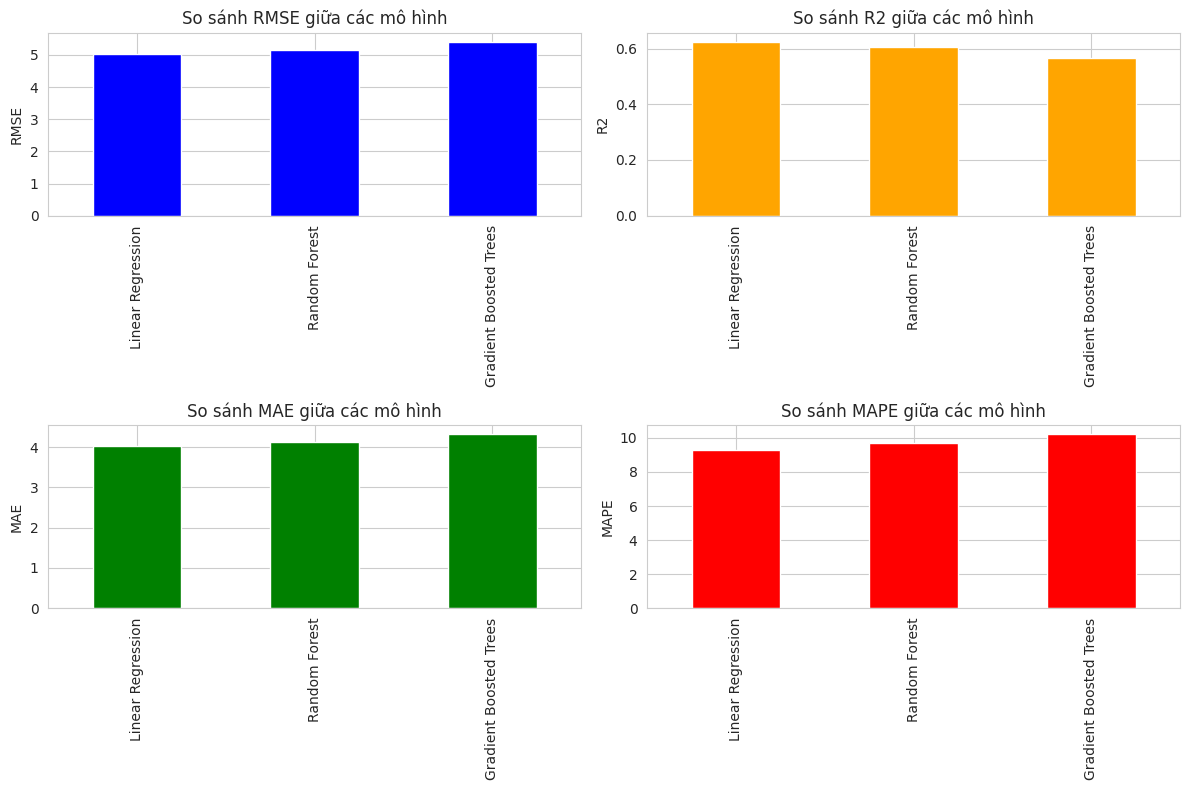

In [10]:
# Chuyển metrics thành DataFrame
res_df = pd.DataFrame(metrics).T.sort_values("RMSE")

# Vẽ biểu đồ so sánh tất cả metrics
fig, axes = plt.subplots(2, 2, figsize=(12,8))
cols = ["RMSE", "R2", "MAE", "MAPE"]
colors = ["blue", "orange", "green", "red"]

for ax, col, c in zip(axes.flatten(), cols, colors):
    res_df[[col]].plot(kind="bar", ax=ax, legend=False, color=c)
    ax.set_title(f"So sánh {col} giữa các mô hình")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

**ĐÁNH GIÁ MÔ HÌNH**

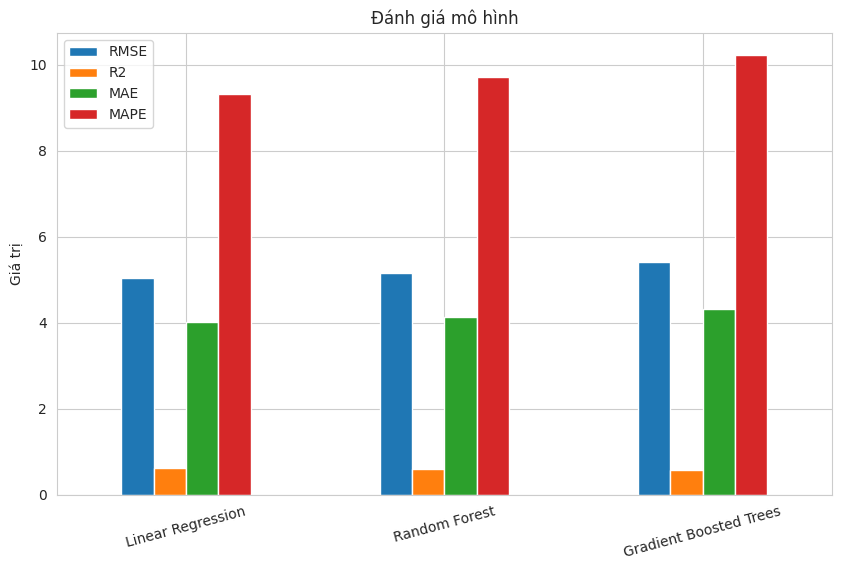

In [11]:
res_df = pd.DataFrame(metrics).T.sort_values("RMSE")

ax = res_df.plot(kind="bar", figsize=(10,6))
ax.set_title("Đánh giá mô hình")
ax.set_ylabel("Giá trị")
plt.xticks(rotation=15)
plt.show()

# **PHÂN TÍCH CHI TIẾT MÔ HÌNH TỐT NHẤT**

**Đánh giá mô hình tốt nhất**

In [12]:
best_model_name = res_df.index[0]
print("Mô hình tốt nhất:", best_model_name)
print("RMSE: {:.2f}".format(metrics[best_model_name]["RMSE"]))
print("MAE : {:.2f}".format(metrics[best_model_name]["MAE"]))
print("R²  : {:.3f}".format(metrics[best_model_name]["R2"]))
print("MAPE: {:.2f}%".format(metrics[best_model_name]["MAPE"]))

best_preds_pdf = predictions_by_model[best_model_name]\
    .select("date","location_name","water_consumption","prediction")\
    .orderBy("date").toPandas()

Mô hình tốt nhất: Linear Regression
RMSE: 5.03
MAE : 4.02
R²  : 0.625
MAPE: 9.32%


**Thực tế vs Dự đoán mức tiêu thụ nước (theo tỉnh)**

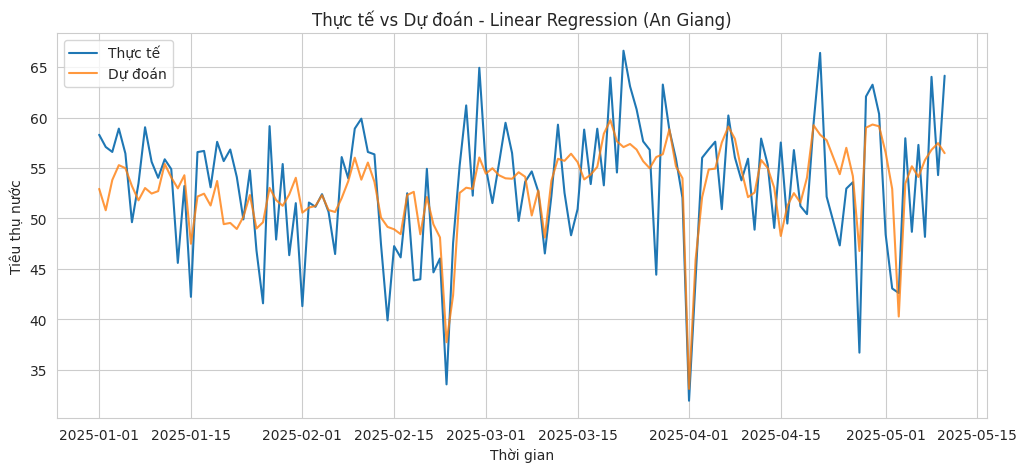

In [37]:
province_pick = best_preds_pdf["location_name"].mode().iat[0]
sub = best_preds_pdf[best_preds_pdf["location_name"]==province_pick].copy()

plt.figure(figsize=(12,5))
plt.plot(sub["date"], sub["water_consumption"], label="Thực tế")
plt.plot(sub["date"], sub["prediction"], label="Dự đoán", alpha=0.8)
plt.title(f"Thực tế vs Dự đoán - {best_model_name} ({province_pick})")
plt.xlabel("Thời gian"); plt.ylabel("Tiêu thụ nước")
plt.legend()
plt.show()

**So sánh giá trị thực tế và dự báo**

In [14]:
best_preds_pdf.head()

,date,location_name,water_consumption,prediction
0,2025-01-01,An Giang,58.295,52.936
1,2025-01-01,Ba Ria-Vung Tau,45.821,42.993
2,2025-01-01,Bac Giang,52.900,49.665
3,2025-01-01,Bac Kan,41.068,44.860
4,2025-01-01,Bac Lieu,39.049,46.847


# **PHÂN TÍCH XU HƯỚNG TIÊU THỤ NƯỚC**

**BOXPLOT KIỂM TRA OUTLIERS**

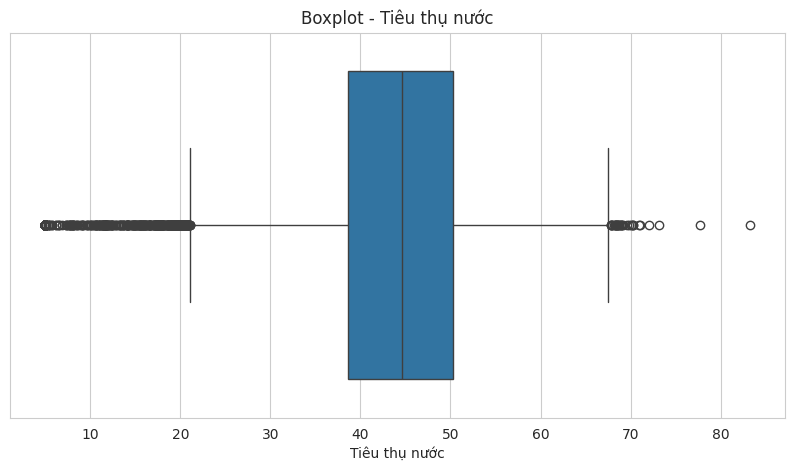

In [15]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df_vn, x="water_consumption")
plt.title("Boxplot - Tiêu thụ nước")
plt.xlabel("Tiêu thụ nước")
plt.show()

**PHÂN TÍCH MỐI QUAN HỆ GIỮA THỜI TIẾT - MỨC TIÊU THỤ NƯỚC**

*MA TRẬN TƯƠNG QUAN*

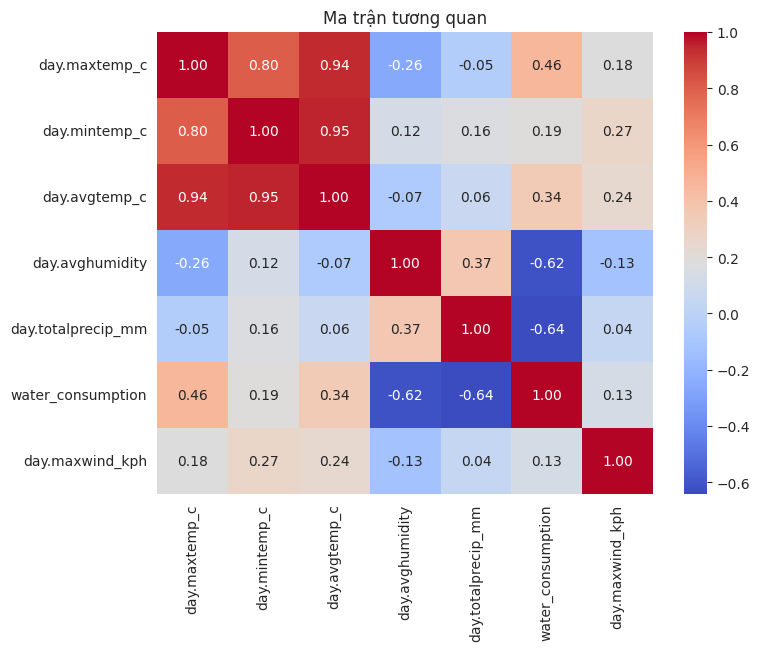

In [16]:
num_cols = ["day.maxtemp_c","day.mintemp_c","day.avgtemp_c","day.avghumidity","day.totalprecip_mm","water_consumption","day.maxwind_kph"]

plt.figure(figsize=(8,6))
sns.heatmap(df_vn[num_cols].corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Ma trận tương quan")
plt.show()

*PHÂN PHỐI TIÊU THỤ NƯỚC*

<Figure size 1200x600 with 0 Axes>

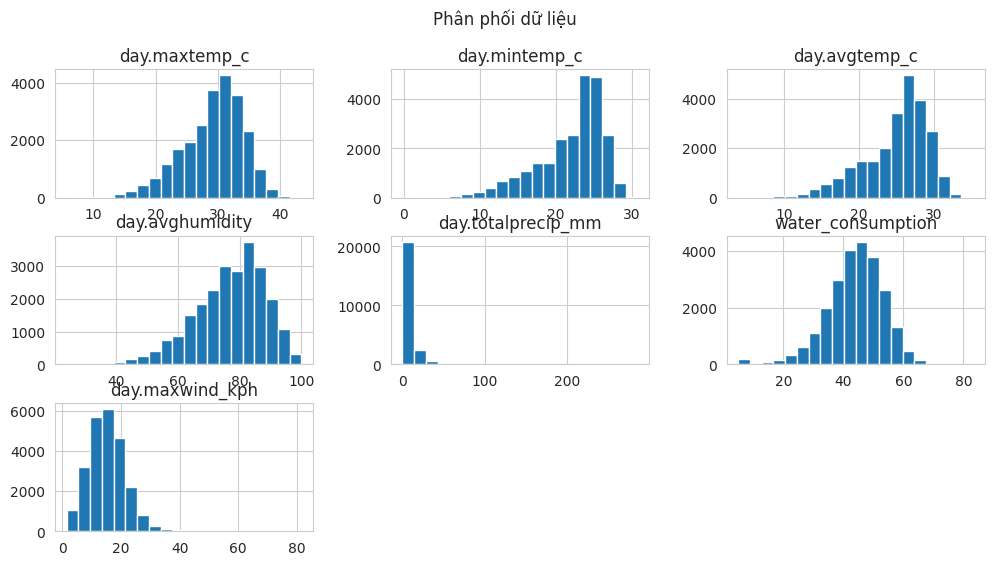

In [17]:
plt.figure(figsize=(12,6))
df_vn[num_cols].hist(bins=20, figsize=(12,6))
plt.suptitle("Phân phối dữ liệu")
plt.show()

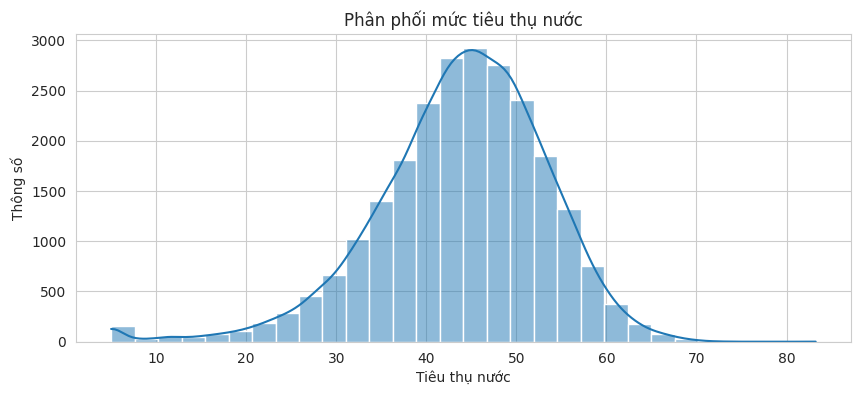

In [18]:
plt.figure(figsize=(10,4))
sns.histplot(df_vn["water_consumption"], bins=30, kde=True)
plt.title("Phân phối mức tiêu thụ nước")
plt.xlabel("Tiêu thụ nước")
plt.ylabel("Thông số")
plt.show()

*NHIỆT ĐỘ TRUNG BÌNH THEO THÁNG*

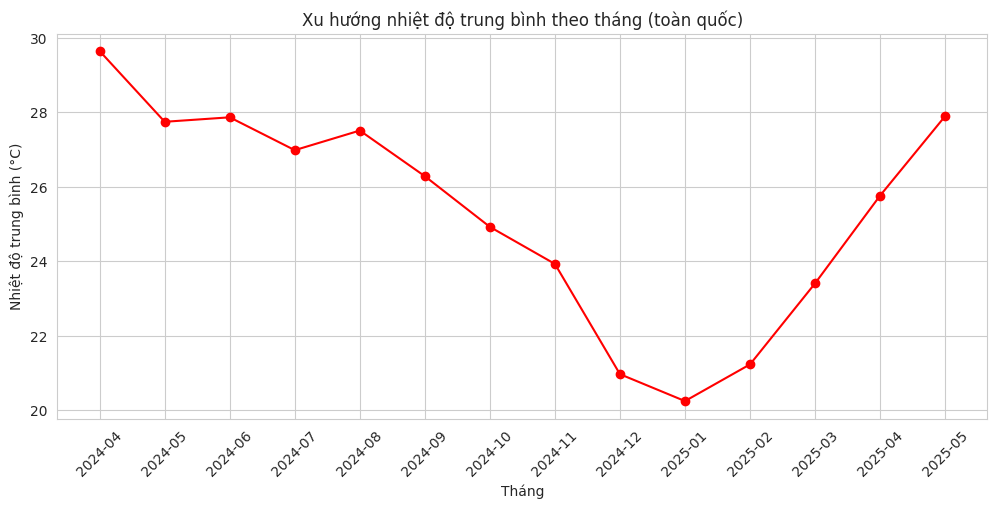

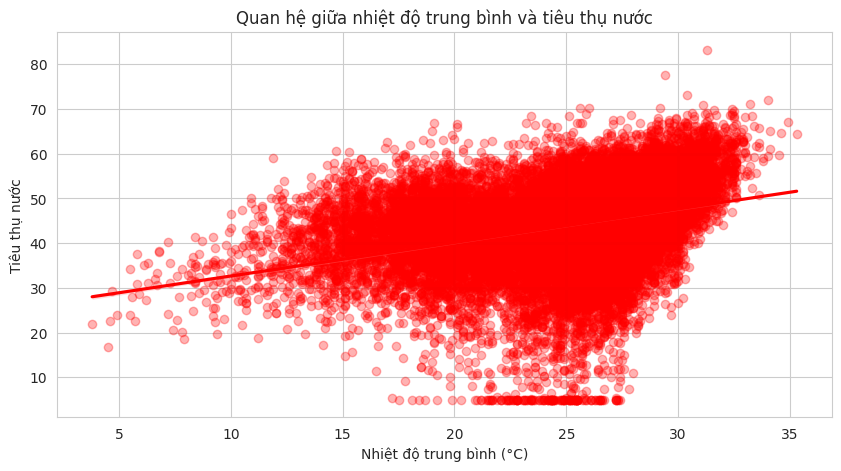

In [19]:
df_temp = df_vn.groupby(df_vn["date"].dt.to_period("M"))["day.avgtemp_c"].mean().reset_index()
df_temp["date"] = df_temp["date"].astype(str)

# Xu hướng nhiệt độ trung bình theo tháng
plt.figure(figsize=(12,5))
plt.plot(df_temp["date"], df_temp["day.avgtemp_c"], marker="o", color="red")
plt.xticks(rotation=45)
plt.title("Xu hướng nhiệt độ trung bình theo tháng (toàn quốc)")
plt.xlabel("Tháng")
plt.ylabel("Nhiệt độ trung bình (°C)")
plt.grid(True)
plt.show()

# Mối quan hệ nhiệt độ & tiêu thụ nước
plt.figure(figsize=(10,5))
sns.regplot(data=df_vn, x="day.avgtemp_c", y="water_consumption", scatter_kws={"alpha":0.3}, color="red")
plt.title("Quan hệ giữa nhiệt độ trung bình và tiêu thụ nước")
plt.xlabel("Nhiệt độ trung bình (°C)")
plt.ylabel("Tiêu thụ nước")
plt.show()

*LƯỢNG MƯA TRUNG BÌNH THEO THÁNG*

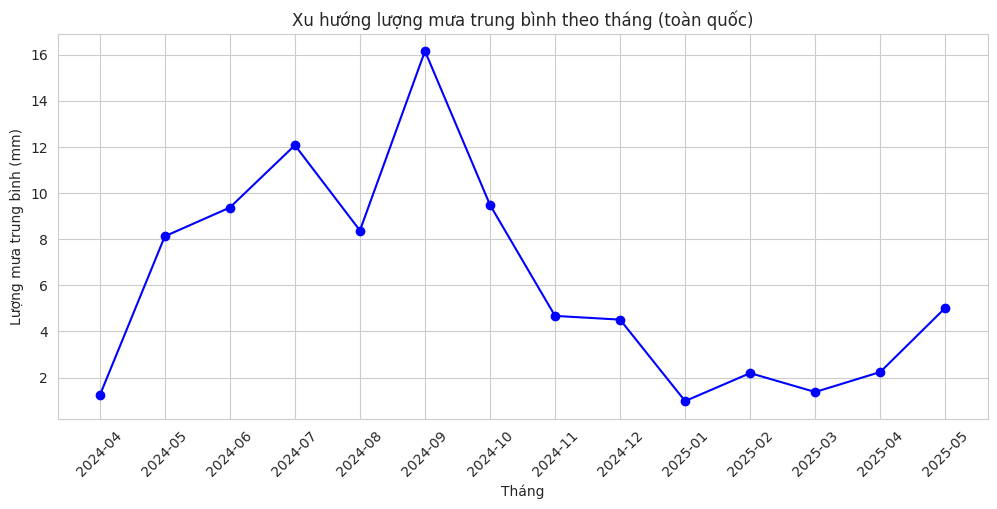

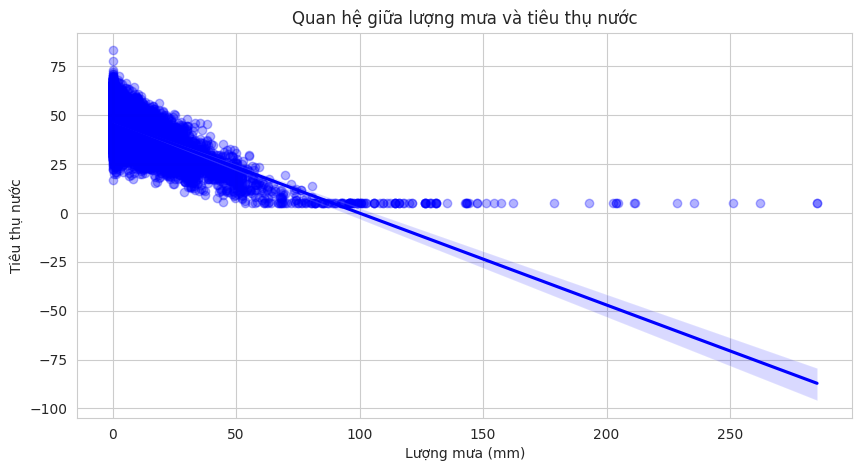

In [20]:
df_rain = df_vn.groupby(df_vn["date"].dt.to_period("M"))["day.totalprecip_mm"].mean().reset_index()
df_rain["date"] = df_rain["date"].astype(str)

# Xu hướng lượng mưa theo tháng
plt.figure(figsize=(12,5))
plt.plot(df_rain["date"], df_rain["day.totalprecip_mm"], marker="o", color="blue")
plt.xticks(rotation=45)
plt.title("Xu hướng lượng mưa trung bình theo tháng (toàn quốc)")
plt.xlabel("Tháng")
plt.ylabel("Lượng mưa trung bình (mm)")
plt.grid(True)
plt.show()

# Mối quan hệ mưa & tiêu thụ nước
plt.figure(figsize=(10,5))
sns.regplot(data=df_vn, x="day.totalprecip_mm", y="water_consumption", scatter_kws={"alpha":0.3}, color="blue")
plt.title("Quan hệ giữa lượng mưa và tiêu thụ nước")
plt.xlabel("Lượng mưa (mm)")
plt.ylabel("Tiêu thụ nước")
plt.show()

*ĐỘ ẨM TRUNG BÌNH THEO THÁNG*

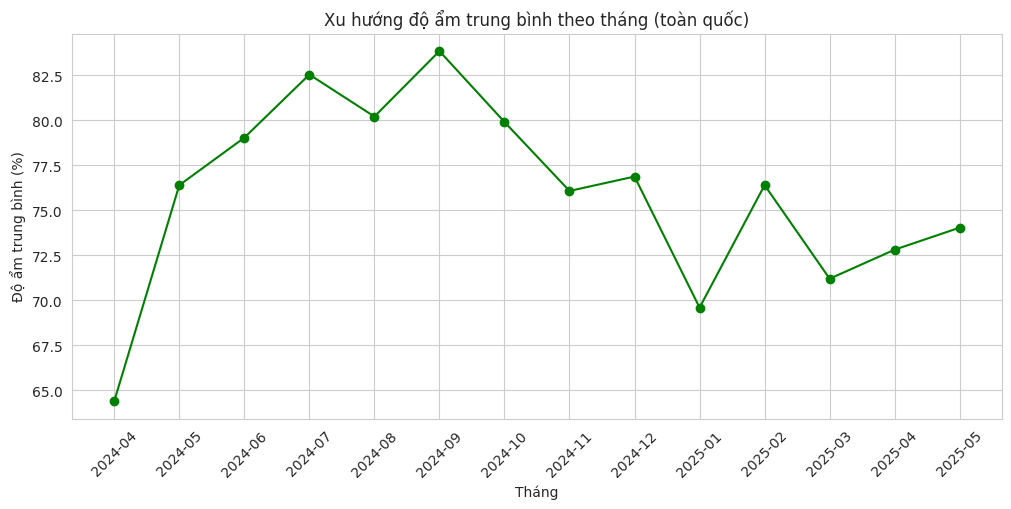

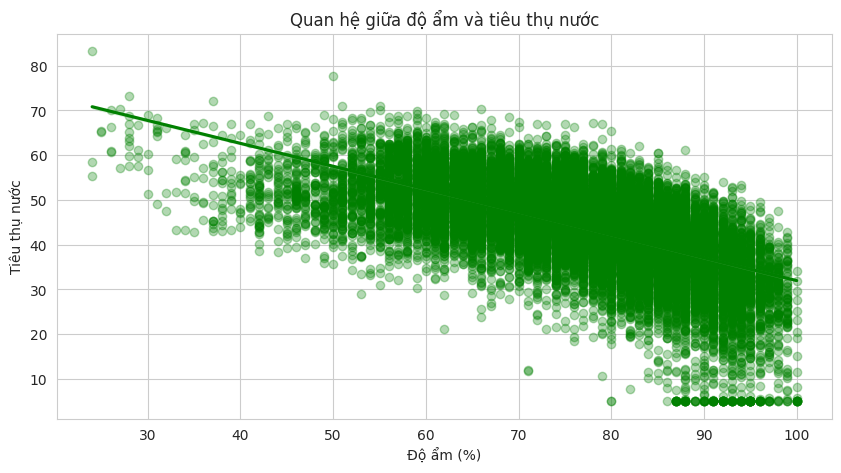

In [21]:
df_hum = df_vn.groupby(df_vn["date"].dt.to_period("M"))["day.avghumidity"].mean().reset_index()
df_hum["date"] = df_hum["date"].astype(str)

# Xu hướng độ ẩm theo tháng
plt.figure(figsize=(12,5))
plt.plot(df_hum["date"], df_hum["day.avghumidity"], marker="o", color="green")
plt.xticks(rotation=45)
plt.title("Xu hướng độ ẩm trung bình theo tháng (toàn quốc)")
plt.xlabel("Tháng")
plt.ylabel("Độ ẩm trung bình (%)")
plt.grid(True)
plt.show()

# Mối quan hệ độ ẩm & tiêu thụ nước
plt.figure(figsize=(10,5))
sns.regplot(data=df_vn, x="day.avghumidity", y="water_consumption", scatter_kws={"alpha":0.3}, color="green")
plt.title("Quan hệ giữa độ ẩm và tiêu thụ nước")
plt.xlabel("Độ ẩm (%)")
plt.ylabel("Tiêu thụ nước")
plt.show()

*SO SÁNH TỔNG HỢP XU HƯỚNG THỜI TIẾT*

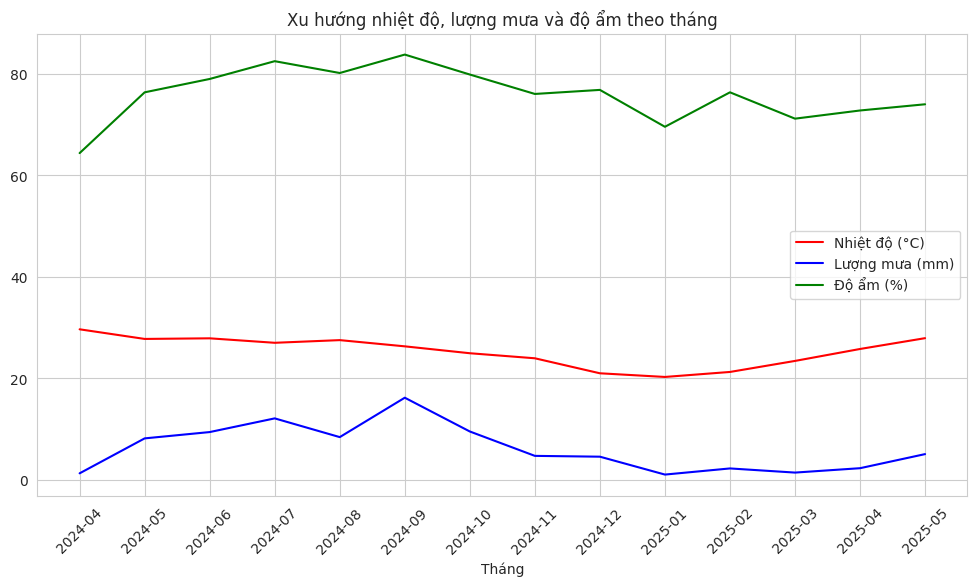

In [22]:
plt.figure(figsize=(12,6))
plt.plot(df_temp["date"], df_temp["day.avgtemp_c"], label="Nhiệt độ (°C)", color="red")
plt.plot(df_rain["date"], df_rain["day.totalprecip_mm"], label="Lượng mưa (mm)", color="blue")
plt.plot(df_hum["date"], df_hum["day.avghumidity"], label="Độ ẩm (%)", color="green")
plt.xticks(rotation=45)
plt.title("Xu hướng nhiệt độ, lượng mưa và độ ẩm theo tháng")
plt.xlabel("Tháng")
plt.legend()
plt.grid(True)
plt.show()

*KẾT LUẬN SƠ BỘ*

Kết luận:
- Khi nhiệt độ trung bình tăng → mức tiêu thụ nước có xu hướng TĂNG.
- Khi lượng mưa tăng → mức tiêu thụ nước có xu hướng GIẢM.
- Khi độ ẩm tăng cao → mức tiêu thụ nước có xu hướng GIẢM NHẸ.


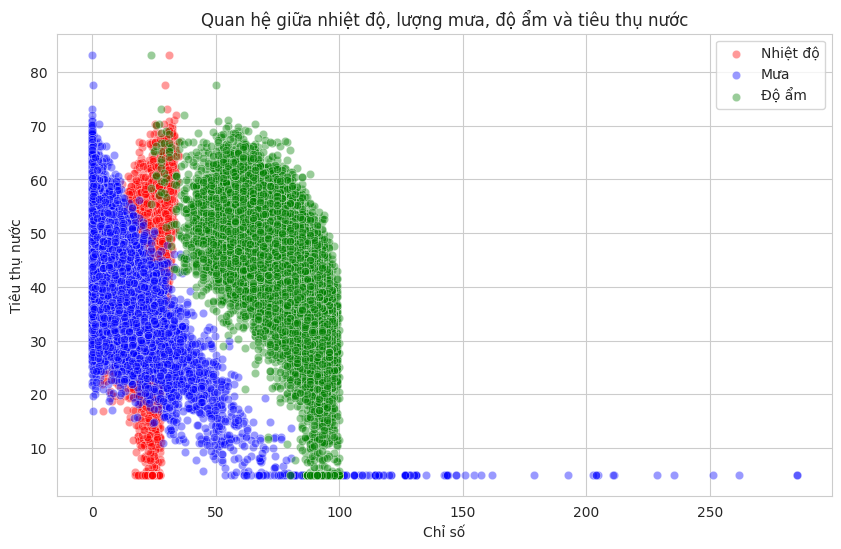

In [23]:
print("Kết luận:")
print("- Khi nhiệt độ trung bình tăng → mức tiêu thụ nước có xu hướng TĂNG.")
print("- Khi lượng mưa tăng → mức tiêu thụ nước có xu hướng GIẢM.")
print("- Khi độ ẩm tăng cao → mức tiêu thụ nước có xu hướng GIẢM NHẸ.")

# Vẽ thêm biểu đồ trực quan hóa quan hệ
plt.figure(figsize=(10,6))
sns.scatterplot(data=df_vn, x="day.avgtemp_c", y="water_consumption", alpha=0.4, color="red", label="Nhiệt độ")
sns.scatterplot(data=df_vn, x="day.totalprecip_mm", y="water_consumption", alpha=0.4, color="blue", label="Mưa")
sns.scatterplot(data=df_vn, x="day.avghumidity", y="water_consumption", alpha=0.4, color="green", label="Độ ẩm")
plt.title("Quan hệ giữa nhiệt độ, lượng mưa, độ ẩm và tiêu thụ nước")
plt.xlabel("Chỉ số")
plt.ylabel("Tiêu thụ nước")
plt.legend()
plt.show()

**XU HƯỚNG TIÊU THỤ NƯỚC THEO THÁNG**

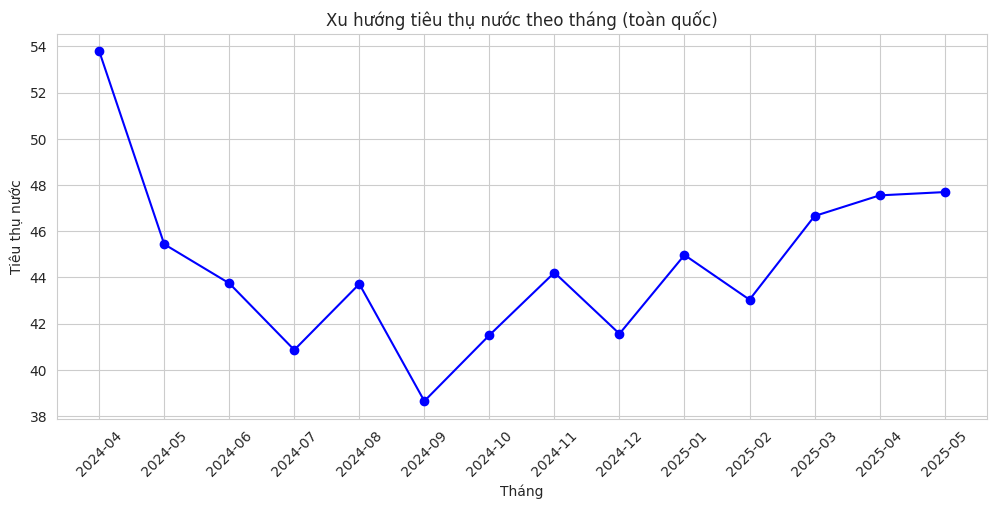

Thống kê tiêu thụ nước theo tháng:


,date,mean,std,min,max
0,1,44.973,7.320,5.000,66.910
1,2,43.040,8.522,13.420,67.914
2,3,46.658,8.597,5.000,70.274
3,4,49.152,8.159,17.549,83.234
4,5,45.990,8.881,5.000,69.190
5,6,43.749,10.172,5.000,68.730
6,7,40.867,10.121,5.000,65.131
7,8,43.719,8.734,5.000,67.375
8,9,38.654,11.497,5.000,62.450
9,10,41.505,9.468,5.000,68.921


In [24]:
df_monthly = df_vn.groupby(df_vn["date"].dt.to_period("M"))["water_consumption"].mean().reset_index()
df_monthly["date"] = df_monthly["date"].astype(str)

plt.figure(figsize=(12,5))
plt.plot(df_monthly["date"], df_monthly["water_consumption"], marker="o", color="blue")
plt.xticks(rotation=45)
plt.title("Xu hướng tiêu thụ nước theo tháng (toàn quốc)")
plt.xlabel("Tháng")
plt.ylabel("Tiêu thụ nước")
plt.grid(True)
plt.show()

monthly_stats = df_vn.groupby(df_vn["date"].dt.month)["water_consumption"].agg(["mean","std","min","max"]).reset_index()
print("Thống kê tiêu thụ nước theo tháng:")
display(monthly_stats)

**TIÊU THỤ NƯỚC THEO MÙA**

/tmp/ipython-input-4122983444.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_vn, x="season", y="water_consumption", palette="Set2")


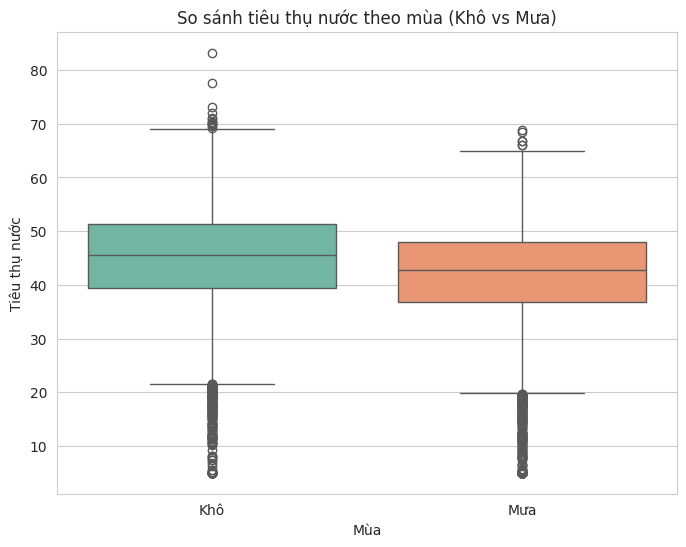

Thống kê tiêu thụ nước theo mùa:


,season,mean,std,min,max,median
0,Khô,44.973,9.160,5.000,83.234,45.568
1,Mưa,41.485,9.965,5.000,68.921,42.758


In [25]:
df_vn["month"] = df_vn["date"].dt.month
df_vn["season"] = np.where(df_vn["month"].isin([1,2,3,4,5,6,7,8]), "Khô", "Mưa")

plt.figure(figsize=(8,6))
sns.boxplot(data=df_vn, x="season", y="water_consumption", palette="Set2")
plt.title("So sánh tiêu thụ nước theo mùa (Khô vs Mưa)")
plt.xlabel("Mùa")
plt.ylabel("Tiêu thụ nước")
plt.show()

season_stats = df_vn.groupby("season")["water_consumption"].agg(["mean","std","min","max","median"]).reset_index()
print("Thống kê tiêu thụ nước theo mùa:")
display(season_stats)

*TỶ LỆ TIÊU THỤ NƯỚC THEO MÙA*

In [26]:
share_by_season = df_vn.groupby("season")["water_consumption"].sum()
share_by_season = 100 * share_by_season / share_by_season.sum()
display(share_by_season)

,water_consumption
season,
Khô,69.951
Mưa,30.049


*KIỂM ĐỊNH SỰ BIẾN THIÊN THEO NHÓM*

In [27]:
from scipy.stats import ttest_ind, f_oneway

dry = df_vn[df_vn["season"]=="Khô"]["water_consumption"]
rainy = df_vn[df_vn["season"]=="Mưa"]["water_consumption"]

t_stat, p_val = ttest_ind(dry, rainy, equal_var=False)
print("T-test mùa khô vs mùa mưa: t=%.3f, p=%.5f" % (t_stat, p_val))

groups = [g["water_consumption"].values for _, g in df_vn.groupby("location.name")]
f_stat, p_val = f_oneway(*groups)
print("ANOVA giữa các tỉnh: F=%.3f, p=%.5f" % (f_stat, p_val))

T-test mùa khô vs mùa mưa: t=25.993, p=0.00000
ANOVA giữa các tỉnh: F=28.054, p=0.00000


**TIÊU THỤ NƯỚC THEO TỈNH**

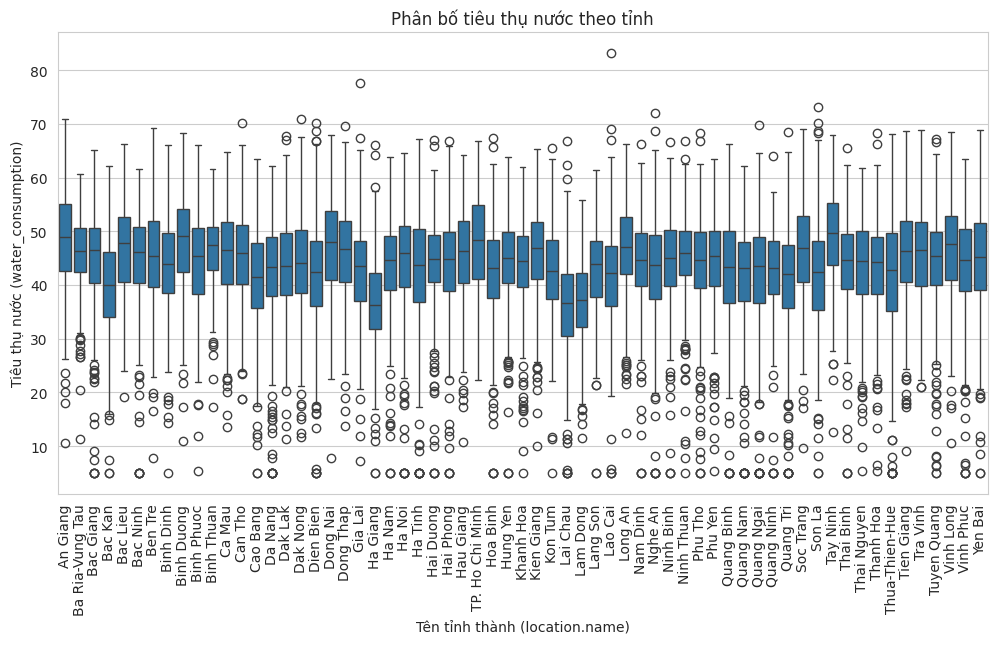

/tmp/ipython-input-768373767.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  metrics_by_province = best_preds_pdf.groupby("location_name").apply(


,location.name,mean,std,min,max,median,RMSE,R2,MAE,MAPE
0,An Giang,48.235,9.118,10.642,71.009,48.984,4.658,0.469,3.800,7.340
1,Ba Ria-Vung Tau,46.003,6.810,11.254,60.728,46.396,4.795,0.107,3.882,8.081
2,Bac Giang,44.898,9.474,5.000,65.168,46.458,5.410,0.412,4.342,10.093
3,Bac Kan,39.629,8.886,5.000,62.121,39.970,5.294,0.489,4.307,11.311
4,Bac Lieu,46.442,8.549,19.103,66.198,47.820,5.380,0.176,4.276,8.677
5,Bac Ninh,44.632,9.284,5.000,61.685,46.094,5.173,0.422,4.247,9.625
6,Ben Tre,45.390,9.115,7.874,69.190,45.454,5.171,0.331,4.179,8.330
7,Binh Dinh,43.933,8.586,5.000,66.064,43.977,4.516,0.485,3.626,9.100
8,Binh Duong,47.834,8.964,10.981,68.312,49.121,4.885,0.187,3.569,6.980
9,Binh Phuoc,44.256,9.537,5.451,66.015,45.323,4.749,0.471,3.830,7.598


In [38]:
from sklearn.metrics import mean_absolute_error, r2_score

plt.figure(figsize=(12,6))
sns.boxplot(data=df_vn, x="location.name", y="water_consumption")
plt.xticks(rotation=90)
plt.xlabel("Tên tỉnh thành (location.name)")
plt.ylabel("Tiêu thụ nước (water_consumption)")
plt.title("Phân bố tiêu thụ nước theo tỉnh")
plt.show()

# Tính toán số liệu theo tỉnh
metrics_by_province = best_preds_pdf.groupby("location_name").apply(
    lambda x: pd.Series({
        "RMSE": sqrt(mean_squared_error(x["water_consumption"], x["prediction"])),
        "R2": r2_score(x["water_consumption"], x["prediction"]),
        "MAE": mean_absolute_error(x["water_consumption"], x["prediction"]),
        "MAPE": np.mean(np.abs((x["water_consumption"] - x["prediction"]) / x["water_consumption"] )) * 100
    })
).reset_index()
metrics_by_province.rename(columns={"location_name": "location_name_metrics"}, inplace=True)

# Tính số liệu thống kê của tỉnh
province_stats = df_vn.groupby("location.name")["water_consumption"].agg(["mean","std","min","max","median"]).reset_index()

province_summary = province_stats.merge(
    metrics_by_province,
    left_on="location.name",
    right_on="location_name_metrics",
    how="left"
).drop(columns=["location_name_metrics"])
display(province_summary.head(10))

In [29]:
share_by_province = df_vn.groupby("location.name")["water_consumption"].sum()
share_by_province = 100 * share_by_province / share_by_province.sum()
print("Top 10 tỉnh có tỷ trọng tiêu thụ nước cao nhất:")
display(share_by_province.sort_values(ascending=False).head(10))

Top 10 tỉnh có tỷ trọng tiêu thụ nước cao nhất:


,water_consumption
location.name,
Tay Ninh,1.773
An Giang,1.746
Binh Duong,1.731
TP. Ho Chi Minh,1.728
Dong Nai,1.706
Long An,1.691
Binh Thuan,1.683
Bac Lieu,1.681
Vinh Long,1.676


# **ĐÁNH GIÁ MÔ HÌNH**

**RESIDUAL PLOT**

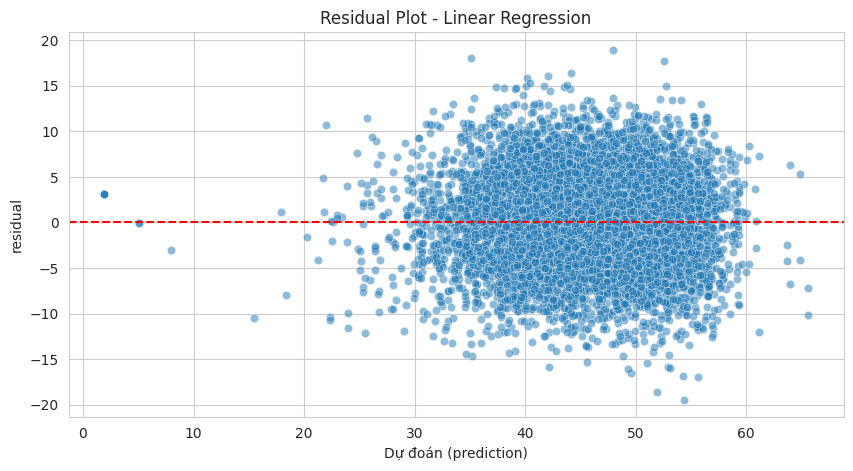

In [30]:
best_preds_pdf["residual"] = best_preds_pdf["water_consumption"] - best_preds_pdf["prediction"]

plt.figure(figsize=(10,5))
sns.scatterplot(data=best_preds_pdf, x="prediction", y="residual", alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Dự đoán (prediction)")
plt.title(f"Residual Plot - {best_model_name}")
plt.show()

**ACTUAL & PREDICTED**

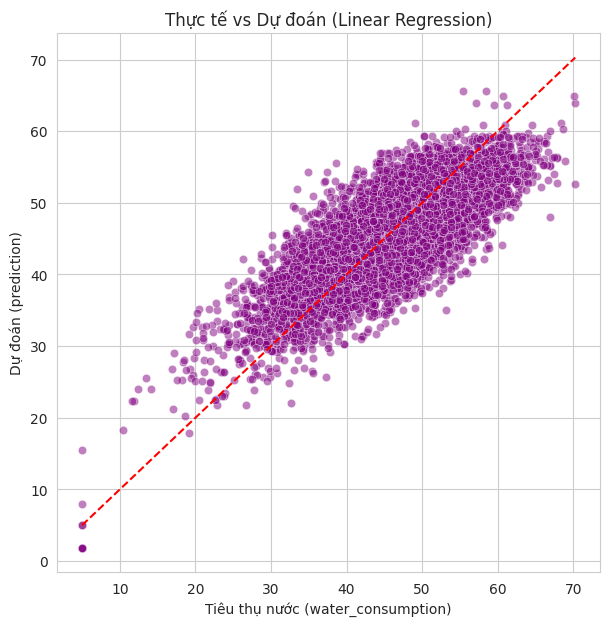

In [31]:
plt.figure(figsize=(7,7))
sns.scatterplot(data=best_preds_pdf, x="water_consumption", y="prediction", alpha=0.5, color="purple")
plt.plot([best_preds_pdf["water_consumption"].min(), best_preds_pdf["water_consumption"].max()],
         [best_preds_pdf["water_consumption"].min(), best_preds_pdf["water_consumption"].max()],color="red", linestyle="--")
plt.xlabel("Tiêu thụ nước (water_consumption)")
plt.ylabel("Dự đoán (prediction)")
plt.title(f"Thực tế vs Dự đoán ({best_model_name})")
plt.show()

**HEATMAP TỈNH - THÁNG**

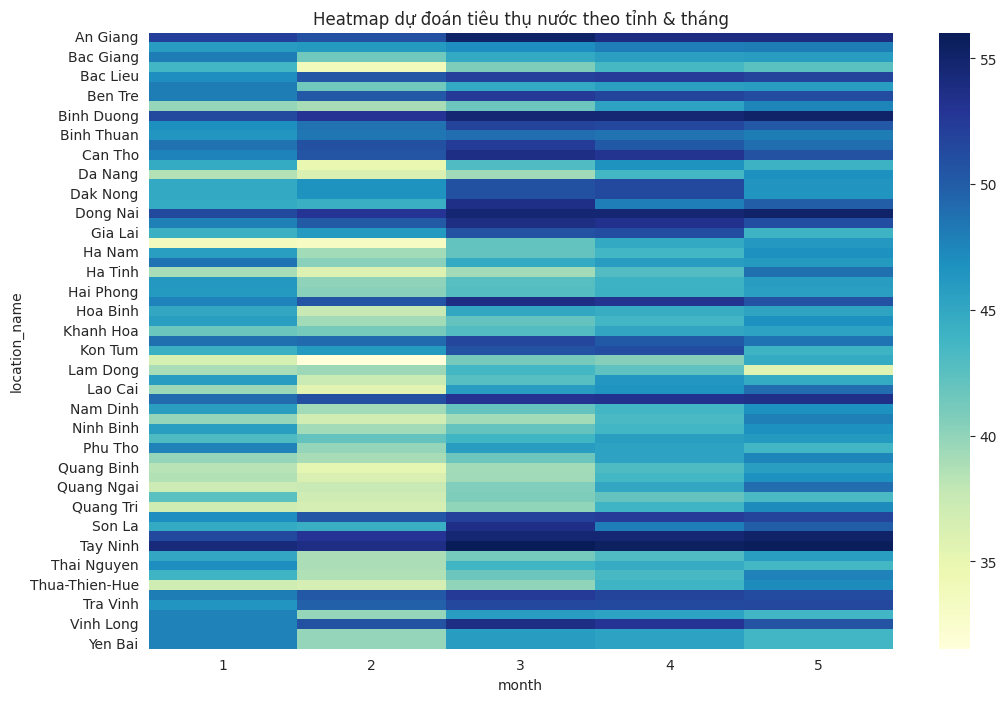

In [32]:
best_preds_pdf["month"] = pd.to_datetime(best_preds_pdf["date"]).dt.month
pivot = best_preds_pdf.groupby(["location_name","month"])["prediction"].mean().reset_index()
pivot_table = pivot.pivot_table(index="location_name", columns="month", values="prediction")

plt.figure(figsize=(12,8))
sns.heatmap(pivot_table, cmap="YlGnBu", annot=False, cbar=True)
plt.title("Heatmap dự đoán tiêu thụ nước theo tỉnh & tháng")
plt.show()

# **TẦM QUAN TRỌNG ĐẶC TRƯNG — RF/GBT**

In [33]:
# Chỉ áp dụng cho mô hình Random Forest hoặc Gradient Boosted Trees
rf_model = RandomForestRegressor(featuresCol="features", labelCol="water_consumption", numTrees=50).fit(train_sdf)

# Lấy tầm quan trọng của đặc trưng
importances = rf_model.featureImportances.toArray()

# Ghép tên cột với giá trị importance
feature_importance = pd.DataFrame({"Feature": feature_cols, "Importance": importances})
feature_importance = feature_importance.sort_values("Importance", ascending=False)
feature_importance["Importance(%)"] = 100 * feature_importance["Importance"] / feature_importance["Importance"].sum()
feature_importance["Cumulative(%)"] = feature_importance["Importance(%)"].cumsum()
display(feature_importance)

,Feature,Importance,Importance(%),Cumulative(%)
4,day_totalprecip_mm,0.484,48.363,48.363
3,day_avghumidity,0.258,25.810,74.172
0,day_maxtemp_c,0.138,13.840,88.012
2,day_avgtemp_c,0.097,9.685,97.698
1,day_mintemp_c,0.018,1.798,99.496
5,day_maxwind_kph,0.005,0.504,100.000


/tmp/ipython-input-1077523644.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance, x="Importance", y="Feature", palette="Blues_r")


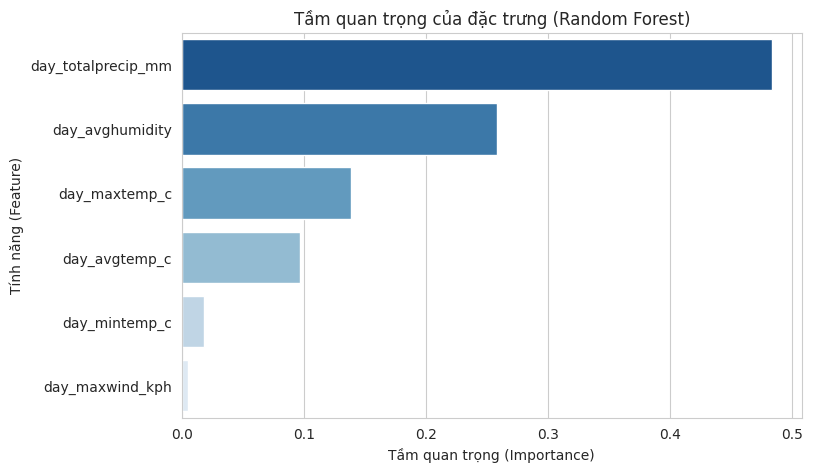

In [34]:
# Vẽ biểu đồ trực quan
plt.figure(figsize=(8,5))
sns.barplot(data=feature_importance, x="Importance", y="Feature", palette="Blues_r")
plt.xlabel('Tầm quan trọng (Importance)')
plt.ylabel('Tính năng (Feature)')
plt.title("Tầm quan trọng của đặc trưng (Random Forest)")
plt.show()

# **BẢN ĐỒ THỰC TẾ TIÊU THỤ NƯỚC CÁC TỈNH**

In [35]:
import branca.colormap as cm

water_by_province = best_preds_pdf.groupby("location_name")["prediction"].mean().reset_index()
water_by_province.rename(columns={"location_name": "Province", "prediction": "AvgWater"}, inplace=True)

province_coords = {}
for index, row in df_vn.iterrows():
    if row["location.name"] not in province_coords:
        province_coords[row["location.name"]] = [row["location.lat"], row["location.lon"]]


colormap = cm.linear.YlOrRd_09.scale(water_by_province["AvgWater"].min(),
                                     water_by_province["AvgWater"].max())

vn_map = folium.Map(location=[16.3, 106], zoom_start=5)

for _, row in water_by_province.iterrows():
    province = row["Province"]
    avg_w = row["AvgWater"]
    coords = province_coords.get(province)
    if coords:
        folium.CircleMarker(
            location=coords,
            radius=8,
            color=colormap(avg_w),
            fill=True,
            fill_color=colormap(avg_w),
            fill_opacity=0.7,
            popup=f"{province}: {avg_w:.1f}"
        ).add_to(vn_map)

colormap.add_to(vn_map)
vn_map